**Làm sắc nét (`cv2.filter2D`)**: kernel tăng đóng góp của pixel trung tâm và trừ một phần các pixel xung quanh, giúp biên nổi bật hơn; có thể khuếch đại nhiễu.


In [1]:
from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import canny as skimage_canny

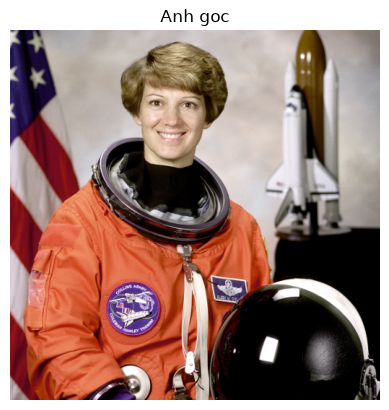

In [2]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

def find_input_dir():
    """Tự tìm thư mục data/input từ vị trí notebook đi ngược lên."""
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        for rel in ("data/input", "lab_2/data/input"):
            p = base / rel
            if p.is_dir():
                return p
    raise FileNotFoundError("Không tìm thấy thư mục data/input của lab_2")

def read_bgr(path):
    """Đọc ảnh, chạy được cả khi đường dẫn có dấu tiếng Việt (Tài liệu, học)."""
    img = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Không đọc được ảnh: {path}")
    return img

INPUT_DIR = find_input_dir()
image_path = INPUT_DIR / "01_astronaut.png"
image_bgr = read_bgr(image_path)
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.title("Anh goc")
plt.axis("off")
plt.show()

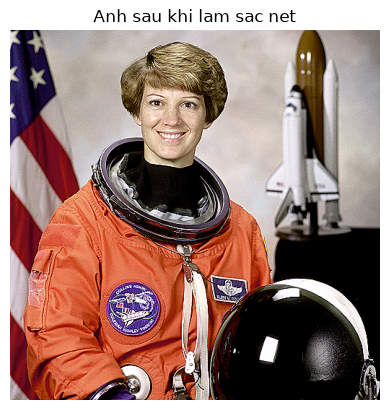

In [3]:
sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

sharpened = cv2.filter2D(image_bgr, -1, sharpen_kernel)

sharpened_rgb = cv2.cvtColor(sharpened, cv2.COLOR_BGR2RGB)

plt.imshow(sharpened_rgb)
plt.title("Anh sau khi lam sac net")
plt.axis("off")
plt.show()

### Nhận xét về vai trò của các hệ số âm/dương trong kernel làm sắc nét ảnh

Kernel làm sắc nét ảnh được sử dụng:

```python
sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)
```

- **Hệ số dương `5` ở trung tâm:** Tăng trọng số của pixel trung tâm, giúp giữ lại và nhấn mạnh chi tiết tại vị trí đang xử lý.
- **Các hệ số âm `-1`:** Trừ đi giá trị của các pixel lân cận ở phía trên, dưới, trái và phải, làm tăng sự khác biệt giữa pixel trung tâm và vùng xung quanh.
- **Các hệ số `0`:** Không sử dụng trực tiếp giá trị của các pixel ở bốn góc trong phép tính.

**Kết luận:** Sự kết hợp giữa hệ số dương ở trung tâm và các hệ số âm xung quanh giúp tăng độ tương phản cục bộ, làm cho đường biên và chi tiết trong ảnh rõ nét hơn. Tuy nhiên, phương pháp này cũng có thể làm nhiễu trong ảnh trở nên nổi bật hơn.

### BT nâng cao 

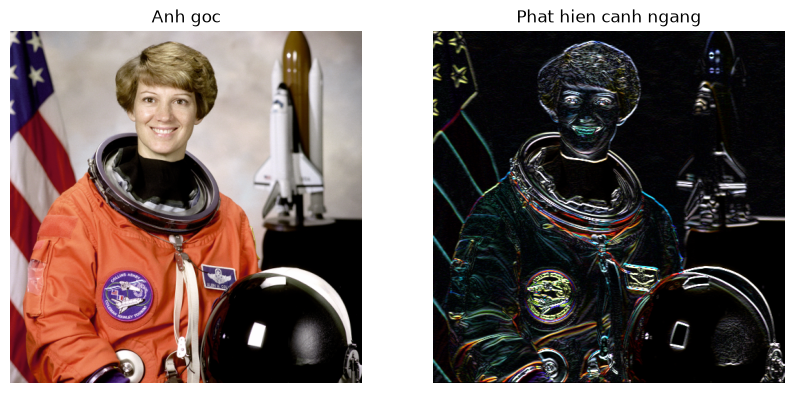

In [4]:
# Kernel phát hiện cạnh ngang
edge_kernel = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
], dtype=np.float32)

# Áp dụng kernel
edge = cv2.filter2D(image_bgr, cv2.CV_32F, edge_kernel)

# Chuyển kết quả về ảnh để hiển thị
edge = cv2.convertScaleAbs(edge)

# Hiển thị kết quả
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Anh goc")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(edge, cv2.COLOR_BGR2RGB))
plt.title("Phat hien canh ngang")
plt.axis("off")

plt.show()

### Nhận xét về kernel phát hiện cạnh ngang

Kernel được thiết kế với các hệ số âm ở hàng trên, hệ số 0 ở hàng giữa và hệ số dương ở hàng dưới. Kernel tính toán sự khác biệt giữa các vùng phía trên và phía dưới của ảnh, từ đó làm nổi bật các đường biên có sự thay đổi cường độ theo chiều dọc. Kết quả giúp quan sát các cạnh ngang trong ảnh.

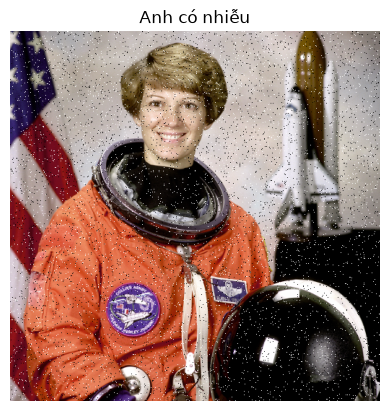

In [5]:
# Tạo ảnh có nhiễu 
noisy = image_bgr.copy()

# Tạo các vị trí nhiễu ngẫu nhiên
noise = np.random.rand(
    image_bgr.shape[0], image_bgr.shape[1]
)

# Thêm nhiễu đen
noisy[noise < 0.02] = 0

# Thêm nhiễu trắng
noisy[noise > 0.98] = 255

# Hiển thị ảnh nhiễu
plt.imshow(cv2.cvtColor(noisy, cv2.COLOR_BGR2RGB))
plt.title("Anh có nhiễu")
plt.axis("off")
plt.show()

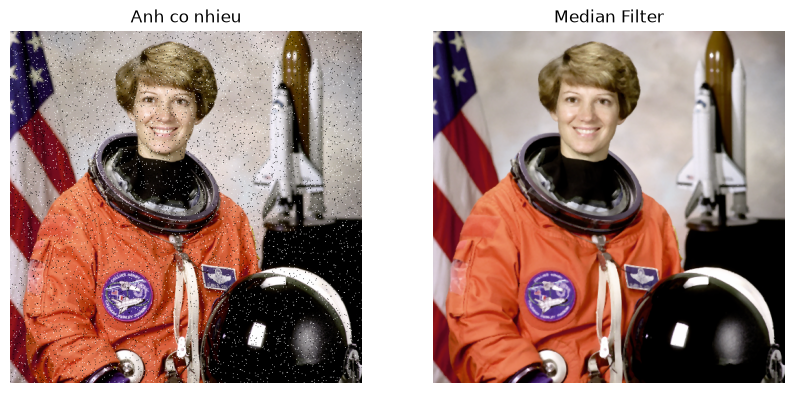

In [6]:
# Lọc trung vị với kernel 3x3
median = cv2.medianBlur(noisy, 3)

# Hiển thị kết quả
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(noisy, cv2.COLOR_BGR2RGB))
plt.title("Anh co nhieu")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(median, cv2.COLOR_BGR2RGB))
plt.title("Median Filter")
plt.axis("off")

plt.show()

### Nhận xét về Median Filter

Median Filter sử dụng giá trị trung vị của các pixel lân cận để thay thế pixel trung tâm. Phương pháp này có khả năng loại bỏ nhiễu muối tiêu hiệu quả, đồng thời giữ được đường biên và hình dạng của các đối tượng tương đối tốt. Tuy nhiên, nếu kích thước kernel quá lớn, các chi tiết nhỏ có thể bị mất.

### So sánh

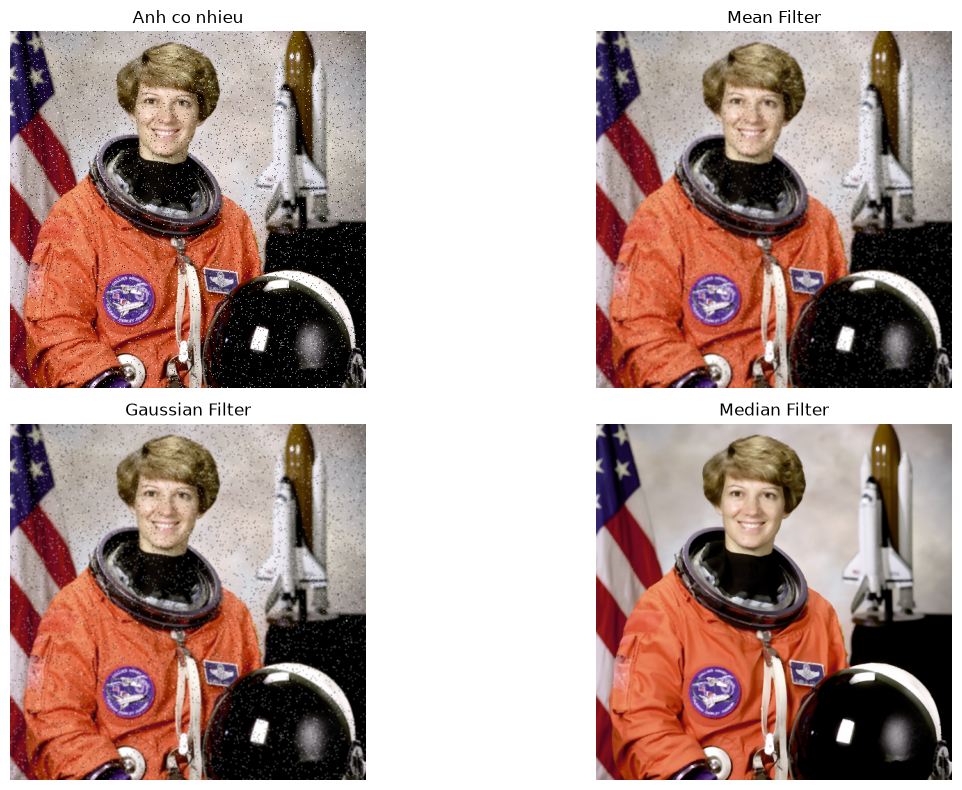

In [7]:
# Mean Filter
mean = cv2.blur(noisy, (3, 3))

# Gaussian Filter
gaussian = cv2.GaussianBlur(noisy, (3, 3), 0)

# Median Filter
median = cv2.medianBlur(noisy, 3)

# So sánh kết quả
plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(noisy, cv2.COLOR_BGR2RGB))
plt.title("Anh co nhieu")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(cv2.cvtColor(mean, cv2.COLOR_BGR2RGB))
plt.title("Mean Filter")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(cv2.cvtColor(gaussian, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Filter")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(median, cv2.COLOR_BGR2RGB))
plt.title("Median Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

### So sánh Mean Filter, Gaussian Filter và Median Filter

| Tiêu chí | Mean Filter | Gaussian Filter | Median Filter |
|---|---|---|---|
| Nguyên lý | Tính trung bình các pixel lân cận | Tính trung bình có trọng số Gaussian | Lấy trung vị các pixel lân cận |
| Giảm nhiễu muối tiêu | Kém hiệu quả | Kém hiệu quả | Hiệu quả |
| Giữ cạnh | Kém, dễ làm mờ cạnh | Tốt hơn Mean trong một số trường hợp, nhưng vẫn làm mờ cạnh | Thường giữ cạnh tốt khi xử lý nhiễu muối tiêu |
| Tốc độ | Nhanh | Nhanh | Phụ thuộc kích thước kernel |

**Kết luận:** Mean và Gaussian Filter có tác dụng làm mượt ảnh nhưng có thể làm mờ đường biên. Median Filter thường phù hợp hơn để xử lý nhiễu muối tiêu và giữ cạnh tương đối tốt. Hiệu quả thực tế phụ thuộc vào loại nhiễu, mức nhiễu và kích thước kernel.